# 03 · Price prediction

**Goal:** estimate a listing's asking price from its location, property type, size and rooms.

**Setup**

* **Target:** `log(price)`. Prices are heavily right-skewed, and errors in property valuation are
  naturally relative (EGP 500k off on a 2M flat is much worse than on a 40M villa). Predictions are
  converted back to EGP for every metric.
* **Features:** `type`, `district`, `compound` (high cardinality, target-encoded), `source`, `area_sqm`,
  `bedrooms`, `bathrooms`. `source` is included because the sources differ by about 3× in price
  level (notebook 02).
* **No leakage:** encoders, scalers and target encoders sit inside scikit-learn `Pipeline`s, so they
  are fit on the training folds only. The test set (20%, stratified by type) is used exactly once,
  at the end.
* **Model selection:** 5-fold cross-validation on the training set.
* **Baselines:** any model must beat (a) the global median price and (b) a *naive appraiser* that
  multiplies area by the median price per m² for the same district and type.

The headline metric is the **median absolute percentage error** (median APE): "half of the
predictions are within X% of the asking price". R² in EGP is also reported, but it is dominated by
the few most expensive listings.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from egypt_real_estate import config, modeling, plotting
from egypt_real_estate.cleaning import load_clean
from egypt_real_estate.plotting import PRIMARY, egp_formatter

plotting.set_style()
listings = load_clean()
X_train, X_test, y_train, y_test = modeling.split(listings)
print(f"train: {len(X_train):,}   test: {len(X_test):,}   features: {list(X_train.columns)}")

train: 49,872   test: 12,468   features: ['type', 'district', 'source', 'compound', 'area_sqm', 'bedrooms', 'bathrooms']


## 1. Compare models

In [2]:
results, fitted = modeling.compare_models(X_train, y_train, X_test, y_test)
results.round(3).to_csv(config.REPORTS_DIR / "model_comparison.csv")

display_cols = ["CV Median APE (%)", "Test Median APE (%)", "Test MAPE (%)", "Test Within 20% (%)",
                "Test MAE (EGP)", "Test R² (log price)", "Test R² (EGP)"]
results[display_cols].round(3)

,CV Median APE (%),Test Median APE (%),Test MAPE (%),Test Within 20% (%),Test MAE (EGP),Test R² (log price),Test R² (EGP)
Model,,,,,,,
Global median (baseline),56.105,55.000,123.166,17.749,6284409.118,-0.005,-0.073
Source × district × type median price/m² (baseline),30.912,30.479,58.121,34.568,3960513.731,0.636,0.544
Ridge regression,28.984,28.883,47.993,35.435,3579720.627,0.706,0.592
Random forest,22.914,22.136,41.141,46.182,3065069.894,0.751,0.657
Gradient boosting (HistGB),24.672,24.004,42.073,42.573,3175568.490,0.748,0.661


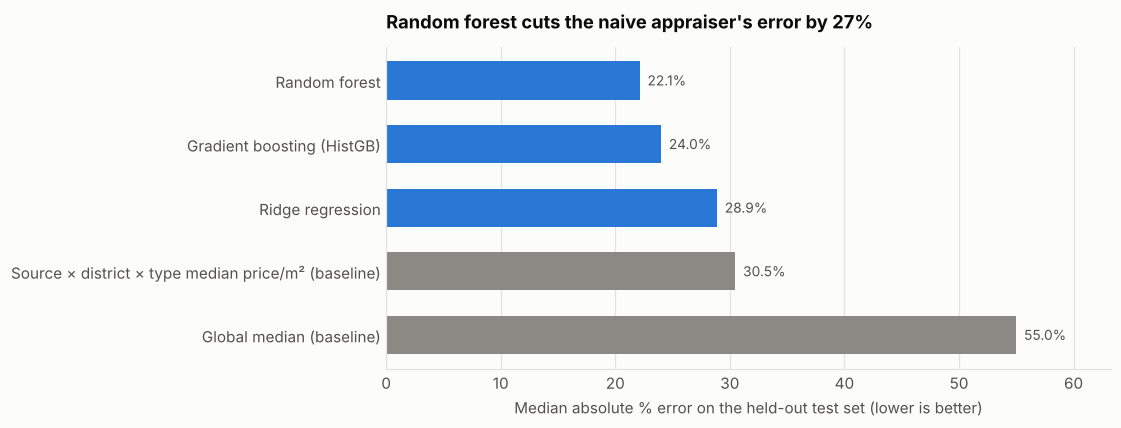

In [3]:
order = results["Test Median APE (%)"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
colors = [plotting.MUTED if "baseline" in m else PRIMARY for m in order.index]
ax.barh(order.index, order.values, color=colors, height=0.6)
for i, v in enumerate(order.values):
    ax.text(v, i, f"  {v:.1f}%", va="center", fontsize=9, color=plotting.TEXT_SECONDARY)
ax.set_xlim(0, order.max() * 1.15)
ax.set_xlabel("Median absolute % error on the held-out test set (lower is better)")
best_model, best_err = order.index[-1], order.iloc[-1]
naive = order[[m for m in order.index if "district" in m][0]]
ax.set_title(f"{best_model} cuts the naive appraiser's error by {1 - best_err / naive:.0%}")
ax.grid(axis="y", visible=False)
plotting.save(fig, "model_comparison")
plt.show()

**Reading the table**

* The **global median** is useless, as expected (median error 55%).
* The **naive appraiser** (median price per m² for the same source, district and type, times
  area) is a strong baseline at about 30%. Most of what determines price is already in that
  lookup.
* **Ridge regression** improves on it only a little (about 29%), because prices don't respond
  linearly to location and size combinations.
* **Random forest** is best, with a median error of about **22%** and R² of 0.75 on log price.
  Almost half of its test predictions fall within ±20% of the asking price. Gradient boosting
  (scikit-learn's `HistGradientBoostingRegressor`, the same family as XGBoost and LightGBM) is
  close behind and scores a slightly higher R² in EGP.
* Cross-validation and test scores agree to within about 1 point, so the models aren't overfitting
  and the test estimate is reliable.

**What changed from the original notebook.** The old version reported R² ≈ 0.60 for a neural
network. It ran PCA on just three numeric columns, fit the scaler, encoder and PCA on the full
dataset before splitting, and was evaluated on data that still contained duplicate listings, so a
listing could be in train and test at the same time. The neural network is dropped here: on tabular
data like this, tree ensembles are the stronger and simpler choice.

## 2. How good is the best model?

Selected by cross-validation: Random forest


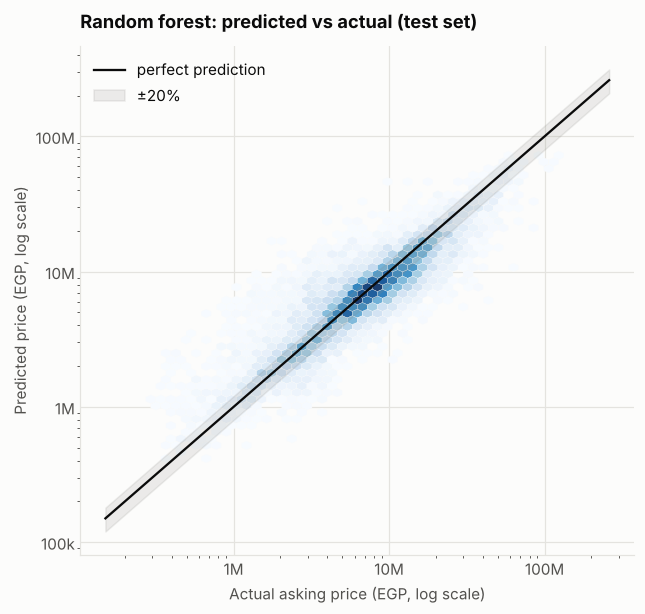

In [4]:
best_name = results["CV Median APE (%)"].idxmin()  # chosen on CV, not on the test set
best = fitted[best_name]
pred = best.predict(X_test)
print(f"Selected by cross-validation: {best_name}")

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.hexbin(y_test, pred, xscale="log", yscale="log", gridsize=50, cmap="Blues", mincnt=2,
          linewidths=0.2, edgecolors=plotting.SURFACE)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
ax.plot(lims, lims, color=plotting.TEXT, linewidth=1.5, label="perfect prediction")
ax.fill_between(lims, [l * 0.8 for l in lims], [l * 1.2 for l in lims], color=plotting.MUTED,
                alpha=0.15, label="±20%")
ax.xaxis.set_major_formatter(egp_formatter)
ax.yaxis.set_major_formatter(egp_formatter)
ax.set_xlabel("Actual asking price (EGP, log scale)")
ax.set_ylabel("Predicted price (EGP, log scale)")
ax.set_title(f"{best_name}: predicted vs actual (test set)")
ax.legend(loc="upper left")
plotting.save(fig, "predicted_vs_actual")
plt.show()

In [5]:
test = X_test.assign(actual=y_test, predicted=pred)
test["ape"] = (test["predicted"] - test["actual"]).abs() / test["actual"] * 100


def error_table(by):
    return (test.groupby(by)
            .agg(listings=("ape", "size"), median_ape=("ape", "median"),
                 within_20pct=("ape", lambda s: (s <= 20).mean() * 100))
            .round(1))


error_table("source")

,listings,median_ape,within_20pct
source,,,
Bayut,6923,23.0,44.8
Cairo,1936,17.5,55.7
OLX,3609,24.1,43.6


In [6]:
error_table("type").sort_values("median_ape")

,listings,median_ape,within_20pct
type,,,
Penthouse,366,18.3,53.3
Townhouse,1062,19.5,51.0
Apartment,5987,20.8,48.7
Duplex,535,21.7,48.0
Twin House,729,21.9,46.4
Chalet,1382,26.8,40.7
Villa,2407,27.1,39.5


In [7]:
big_districts = test["district"].value_counts().head(12).index
error_table("district").loc[big_districts].sort_values("median_ape")

,listings,median_ape,within_20pct
district,,,
Rehab City,190,14.0,62.6
Madinaty,564,17.6,54.1
Nasr City,163,19.8,50.3
New Cairo,4332,19.9,50.3
Mostakbal City,743,21.0,47.8
New Capital,549,23.2,43.5
Sheikh Zayed,1153,23.3,44.3
North Coast,1325,24.8,42.6
Shorouk City,452,24.8,41.6


## 3. What drives the prediction?

Permutation importance: how much the test-set R² (log price) drops when one feature is shuffled.
Shuffling breaks the link between the feature and the price, so a large drop means the model relies
on it.

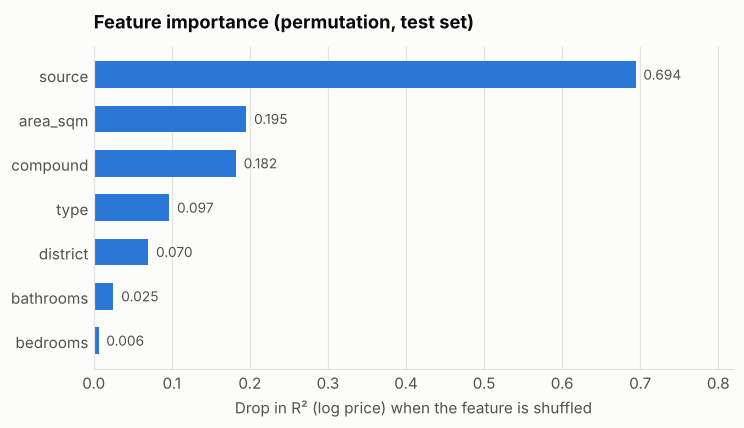

,0
source,0.694
area_sqm,0.195
compound,0.182
type,0.097
district,0.070
bathrooms,0.025
bedrooms,0.006


In [8]:
importance = modeling.feature_importance(best, X_test, y_test)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
imp = importance.sort_values()
ax.barh(imp.index, imp.values, color=PRIMARY, height=0.6)
for i, v in enumerate(imp.values):
    ax.text(max(v, 0), i, f"  {v:.3f}", va="center", fontsize=9, color=plotting.TEXT_SECONDARY)
ax.set_xlim(0, imp.max() * 1.18)
ax.set_xlabel("Drop in R² (log price) when the feature is shuffled")
ax.set_title("Feature importance (permutation, test set)")
ax.grid(axis="y", visible=False)
plotting.save(fig, "feature_importance")
plt.show()
importance.round(3)

## Conclusions

* **Best model: random forest**, selected by cross-validation. On the held-out test set it has a
  median absolute error of about 22% and R² of 0.75 on log price (0.66 in EGP). It beats the
  naive appraiser by roughly a quarter.
* **Source matters most.** Shuffling `source` hurts the model more than any other feature, which
  confirms that the sources' price levels must be modelled, not pooled. After that come **area**,
  **compound** and **property type**. The compound adds a lot on top of the district because
  developments in the same district vary widely in price.
* **Bedrooms add almost nothing** once area is known, matching the correlations in notebook 02.
* **Errors are smallest** in large, homogeneous markets (Rehab, Madinaty, New Cairo: 14–20%) and for
  apartments and townhouses. They are **largest** for villas, chalets and resort areas (Ain Sokhna,
  North Coast), where view, beach access and finishing drive price, and those aren't in the data.

**Limitations.** About 22% median error is near the limit of what these columns allow. The
datasets have no finishing level, floor, view, delivery date, payment plan or listing date, and
these explain much of the price gap between similar units. The model predicts **asking** prices,
not transaction prices, and each source reflects the market at the time it was scraped.